# Actividad 5 · Preparación, entrenamiento y MLflow
Práctica académica reproducible con el dataset público Breast Cancer Wisconsin (Diagnostic). No utilizar como herramienta clínica.

In [1]:
# Fase 1. Entorno y dataset público

%pip -q install mlflow scikit-learn pandas matplotlib scipy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 974.0 kB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 1.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 40.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 38.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 38.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 11.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1

In [3]:
# Importar librerías

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from scipy.stats import ttest_rel
Path('datos').mkdir(exist_ok=True)
Path('resultados').mkdir(exist_ok=True)
print('MLflow:', mlflow.__version__)

MLflow: 3.17.1


In [4]:
# Fase 2. Calidad y preparación
# El dataset original ya es numérico y no presenta valores faltantes. Verificamos estas condiciones antes de decidir cualquier transformación.

original = load_breast_cancer(as_frame=True).frame
original.to_csv('datos/datos_ini.csv', index=False)
limpio = original.drop_duplicates().copy()
limpio.to_csv('datos/datos_limp.csv', index=False)
print('Original:', original.shape, '| Limpio:', limpio.shape)
print('Nulos:', original.isna().sum().sum(), '| Duplicados eliminados:', len(original)-len(limpio))
display(limpio.head())

Original: (569, 31) | Limpio: (569, 31)
Nulos: 0 | Duplicados eliminados: 0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


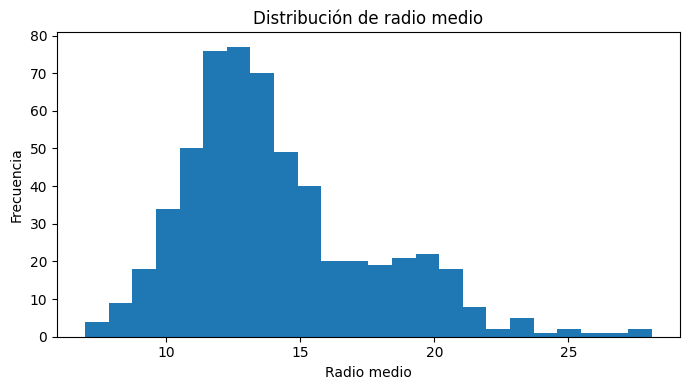

Clases: {1: 357, 0: 212}


In [5]:
# Fase 3. Exploración visual

plt.figure(figsize=(7,4))
plt.hist(limpio['mean radius'], bins=24)
plt.title('Distribución de radio medio')
plt.xlabel('Radio medio'); plt.ylabel('Frecuencia')
plt.tight_layout(); plt.savefig('resultados/distribucion.png'); plt.show()
print('Clases:', limpio['target'].value_counts().to_dict())

In [6]:
# Fase 4. Dos modelos y búsqueda de hiperparámetros
# El escalado se realiza dentro del pipeline para evitar fuga de datos durante la validación cruzada.

X = limpio.drop(columns='target')
y = limpio['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
modelos = {
    'Regresión logística': (Pipeline([('escala', StandardScaler()), ('modelo', LogisticRegression(max_iter=2000, random_state=42))]), {'modelo__C': [0.1, 1, 10]}),
    'Random Forest': (Pipeline([('modelo', RandomForestClassifier(random_state=42, n_jobs=-1))]), {'modelo__n_estimators': [100, 200], 'modelo__max_depth': [None, 6]})
}

In [10]:
# Fase 5. Entrenamiento, métricas y registro en MLflow
import os
os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"

mlflow.set_tracking_uri('file:' + str(Path('mlruns').resolve()))
mlflow.set_experiment('Actividad5_Comparacion')
resultados = []
puntajes_cv = {}
for nombre, (modelo, parametros) in modelos.items():
    ajuste = GridSearchCV(modelo, parametros, cv=cv, scoring='f1', n_jobs=-1)
    ajuste.fit(X_train, y_train)
    pred = ajuste.predict(X_test)
    prob = ajuste.predict_proba(X_test)[:, 1]
    metricas = {'accuracy': accuracy_score(y_test,pred), 'precision': precision_score(y_test,pred),
                'recall': recall_score(y_test,pred), 'f1': f1_score(y_test,pred), 'roc_auc': roc_auc_score(y_test,prob)}
    puntajes_cv[nombre] = cross_val_score(ajuste.best_estimator_, X_train, y_train, cv=cv, scoring='f1')
    with mlflow.start_run(run_name=nombre):
        mlflow.log_params({k: str(v) for k,v in ajuste.best_params_.items()})
        mlflow.log_metrics(metricas)
        mlflow.log_metric('f1_cv_media', float(puntajes_cv[nombre].mean()))
        # Guardar el modelo entrenado en MLflow
        mlflow.sklearn.log_model(modelo, name="modelo", serialization_format="cloudpickle")
        mlflow.log_artifact('datos/datos_limp.csv')
    resultados.append({'modelo':nombre, **metricas, 'parametros':str(ajuste.best_params_)})
    print(nombre, '→ F1:', round(metricas['f1'],4))
comparacion = pd.DataFrame(resultados)
comparacion.to_csv('resultados/comparacion_modelos.csv',index=False)
display(comparacion)

2026/10/18 01:48:07 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Regresión logística → F1: 0.9793


2026/10/18 01:48:31 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Random Forest → F1: 0.9655


,modelo,accuracy,precision,recall,f1,roc_auc,parametros
0,Regresión logística,0.973684,0.972603,0.986111,0.979310,0.995701,{'modelo__C': 0.1}
1,Random Forest,0.956140,0.958904,0.972222,0.965517,0.993056,"{'modelo__max_depth': None, 'modelo__n_estimat..."


t pareada exploratoria: 2.0784 | p: 0.1062


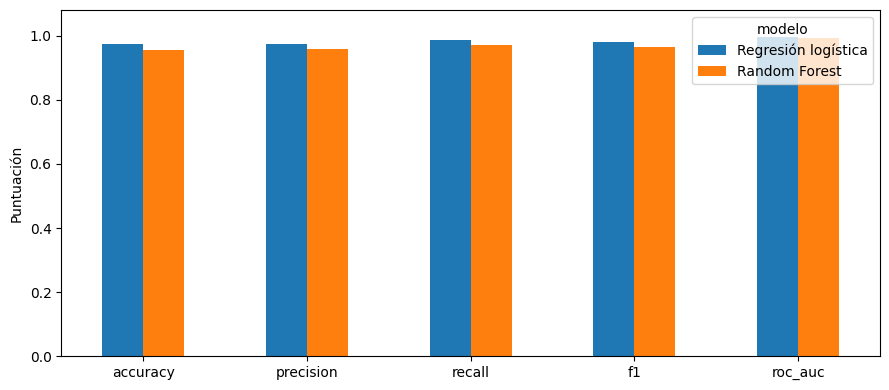

In [11]:
# Fase 6. Comparación estadística y gráfica
# La prueba sobre cinco folds es exploratoria porque sus particiones no son independientes.

prueba = ttest_rel(puntajes_cv['Regresión logística'], puntajes_cv['Random Forest'])
print('t pareada exploratoria:', round(prueba.statistic,4), '| p:', round(prueba.pvalue,4))
comparacion.set_index('modelo')[['accuracy','precision','recall','f1','roc_auc']].T.plot(kind='bar', figsize=(9,4))
plt.ylim(0,1.08);plt.ylabel('Puntuación');plt.xticks(rotation=0);plt.tight_layout()
plt.savefig('resultados/metricas.png');plt.show()

In [12]:
# Fase 7. Evidencia de MLflow y exportación
# Captura la tabla de ejecuciones y sus métricas; para evidenciar el modelo registrado, abre también los artefactos de cada ejecución.

runs = mlflow.search_runs(search_all_experiments=True)
columnas = [c for c in runs.columns if c == 'tags.mlflow.runName' or c.startswith('metrics.')]
display(runs[columnas])
print('Carpetas generadas: datos/, resultados/, mlruns/')

,metrics.f1_cv_media,metrics.f1,metrics.precision,metrics.accuracy,metrics.recall,metrics.roc_auc,tags.mlflow.runName
0,0.970027,0.965517,0.958904,0.956140,0.972222,0.993056,Random Forest
1,0.986116,0.979310,0.972603,0.973684,0.986111,0.995701,Regresión logística
2,0.970027,0.965517,0.958904,0.956140,0.972222,0.993056,Random Forest
3,0.986116,0.979310,0.972603,0.973684,0.986111,0.995701,Regresión logística


Carpetas generadas: datos/, resultados/, mlruns/


In [13]:
# Descargar los resultados y registros de MLflow en un solo ZIP.
import shutil
shutil.make_archive('Actividad5_evidencias', 'zip', '.', 'resultados')
print('Archivo: Actividad5_evidencias.zip')

Archivo: Actividad5_evidencias.zip
